# Workflow for Structure Prediction on the OpenBind Blind Challenge 1

This notebook demonstrates a lightweight, CPU-friendly tutorial workflow. The goal is to show how to:

1. Load the blinded ligand list
2. Prepare the data for prediction using a local FASTA sequence
3. Run exploratory data analysis on actives and fragments
4. Inspect a pre-generated Boltz-2 protein-ligand complex
5. Understand comparison/scoring against reference structures
6. Prepare and validate a submission file

Because running a full structure prediction pipeline is difficult to do in a lightweight Jupyter workflow, we focus on data preparation, quality checks, and submission-ready formatting.

In [1]:
from pathlib import Path
import zipfile

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, rdMolDescriptors
from rdkit.Chem.Scaffolds import MurckoScaffold 

from matplotlib.offsetbox import OffsetImage, AnnotationBbox

In [2]:
tqdm.pandas()
sns.set_style("whitegrid")
sns.set_context("notebook")

In [3]:
# Optional packages used in later cells
try:
    import nglview as nv
except Exception:
    nv = None

try:
    import biotite.structure.io as strucio
except Exception:
    strucio = None

## 1. Loading the data
Load the blinded ligand list directly from Hugging Face.

In [ ]:
test_structure = pd.read_csv(
    "hf://datasets/openadmet/openbind-blind-challenge-1/openbind-blind-challenge-1-TEST-BLINDED.csv"
)
test_structure.head()

## 2. Preparing the data for prediction

The main input is the ligand SMILES list so preprocessing is minimal:

- Keep molecule identifiers and SMILES.
- Parse SMILES into RDKit molecules.
- Define the protein context for the structure-generation pipeline.

In [ ]:
required_cols = ["Molecule_Name", "SMILES"]
missing_cols = [col for col in required_cols if col not in test_structure.columns]
if missing_cols:
    raise ValueError(f"Missing required columns in test_structure: {missing_cols}")

structure_df = test_structure[required_cols].copy().rename(columns={"Molecule_Name": "id", "SMILES": "SMILES"})
structure_df["mol"] = structure_df["SMILES"].apply(Chem.MolFromSmiles)

invalid_smiles = structure_df["mol"].isna().sum()
print(f"Total ligands: {len(structure_df)}")
print(f"Invalid SMILES: {invalid_smiles}")
structure_df.head()

### Load the NS2B-NS3 protein sequence from a FASTA file

For this tutorial, we include a local FASTA file the Zika protein sequence from a local FASTA file stored in `inputs/NS2B-NS3_protein_sequence.fasta`.

This FASTA contains a **monomeric** NS2B-NS3 sequence. No additional chain information is needed for the challenge submission.

In [ ]:
fasta_path = Path("../inputs/NS2B-NS3_protein_sequence.fasta")

if not fasta_path.exists():
    raise FileNotFoundError(f"Missing FASTA file: {fasta_path}")

fasta_text = fasta_path.read_text().strip()
fasta_lines = fasta_text.splitlines()
fasta_header = fasta_lines[0]
ns2b_sequence = "".join(line.strip() for line in fasta_lines[1:])

print(fasta_header)
print(f"Sequence length: {len(ns2b_sequence)} aa")
display(fasta_text)

>29HN_2|Chain B|Genome polyprotein|Zika virus (64320)
Sequence length: 277 aa


'>29HN_2|Chain B|Genome polyprotein|Zika virus (64320)\nMKEVKKGETTDGVYRVMTRRLLGSTQVGVGVMQEGVFHTMWHVTKGAALRSGEGRLDPYWGDVKQDLVSYCGPWKLDAAWDGLSEVQLLAVPPGERAKNIQTLPGIFKTKDGDIGAVALDYPAGTSGSPILDKCGRVIGLYGNGVVIKNGSYVSAITQGKREEETPVE\n>29HN_1|Chain A|Serine protease subunit NS2B|Zika virus (64320)\nSMGKSVDMYIERAGDITWEKDAEVTGNSPRLDVALDESGDFSLVEE'

## 3. Exploratory data analysis

Before moving to structure prediction, we first inspect the blinded ligand set.

In this section we will:

1. Visualize a sample of ligand structures with RDKit
2. Estimate scaffold diversity using Murcko scaffolds
3. Plot the top recurring scaffolds
4. Summarize key descriptor distributions (MW, LogP, TPSA, heavy atoms)

In [ ]:
eda_df = structure_df.dropna(subset=["mol"]).copy()
print(f"Valid molecules: {len(eda_df)} / {len(structure_df)}")

if eda_df.empty:
    raise ValueError("No valid molecules available. Check SMILES parsing in step 2.")

sample_n = min(24, len(eda_df))
sample_mols = eda_df["mol"].head(sample_n).tolist()
sample_legends = eda_df["id"].head(sample_n).tolist()

img = Draw.MolsToGridImage(
    sample_mols,
    molsPerRow=6,
    subImgSize=(220, 180),
    legends=sample_legends,
)
img

To analyze structural diversity, we compute **Bemis–Murcko scaffolds** for each ligand and count unique scaffold chemotypes.

In [8]:
eda_df["murcko_mol"] = eda_df["mol"].apply(
    lambda molecule: MurckoScaffold.GetScaffoldForMol(molecule) if molecule is not None else None
)
eda_df["murcko_smiles"] = eda_df["murcko_mol"].apply(
    lambda scaffold: Chem.MolToSmiles(scaffold) if scaffold is not None else ""
)

# Keep non-empty scaffolds for counting
murcko_series = eda_df.loc[eda_df["murcko_smiles"] != "", "murcko_smiles"]
num_unique_scaffolds = murcko_series.nunique()
print(f"Number of unique Murcko scaffolds: {num_unique_scaffolds}")

Number of unique Murcko scaffolds: 228


Now we visualize the most frequent scaffolds. The bar chart shows scaffold counts, and scaffold images are overlaid below each bar for quick structural interpretation.

In [9]:
def add_scaffold_images(axis, smiles_list, image_size=(120, 120), zoom=0.5, y_offset=-60):
    for index, smiles in enumerate(smiles_list):
        if not smiles:
            continue

        molecule = Chem.MolFromSmiles(smiles)
        if molecule is None:
            continue

        scaffold_image = Draw.MolToImage(molecule, size=image_size)
        image_box = OffsetImage(scaffold_image, zoom=zoom)
        annotation = AnnotationBbox(
            image_box,
            (index, 0),
            xybox=(0, y_offset),
            xycoords=("data", "data"),
            boxcoords="offset points",
            frameon=False,
        )
        axis.add_artist(annotation)

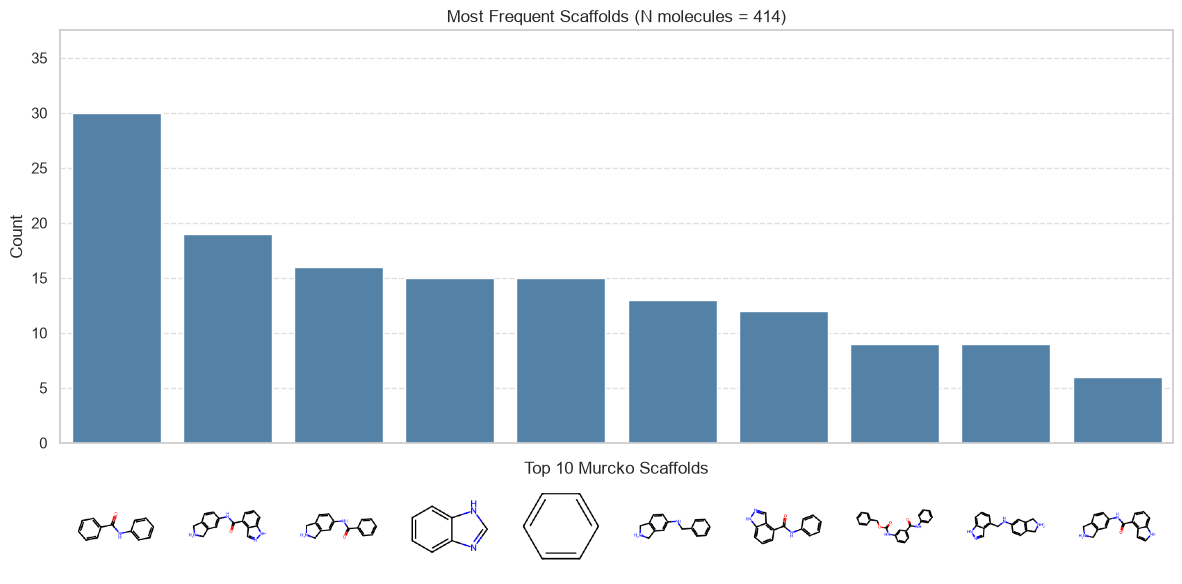

In [10]:
top_n = 10
scaffold_counts = murcko_series.value_counts().head(top_n)
scaffolds_df = scaffold_counts.rename_axis("smiles").reset_index(name="count")

fig, axis = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=scaffolds_df,
    x=scaffolds_df.index,
    y="count",
    color="steelblue",
    ax=axis,
)

add_scaffold_images(axis, scaffolds_df["smiles"])

axis.set_ylabel("Count")
axis.set_xlabel(f"Top {top_n} Murcko Scaffolds")
axis.set_title(f"Most Frequent Scaffolds (N molecules = {len(eda_df)})")
axis.set_xticklabels([])
axis.set_ylim(0, scaffolds_df["count"].max() * 1.25)
axis.grid(axis="y", linestyle="--", alpha=0.6)
fig.subplots_adjust(bottom=0.22)
plt.tight_layout()

## 4. Generating a protein–ligand structure

For this tutorial, we avoid running a heavy structure-prediction model and instead use a **pre-generated Boltz-2 co-folded prediction**.

To generate a protein–ligand structure with Boltz-2, you need a `YAML` input file containing the protein sequence and ligand SMILES. In the cells below, we create that YAML directly from:

- the local NS2B-NS3 FASTA sequence
- the SMILES of a specific ligand from the blinded structure set (we use `blind_challenge_001` as an example)

We then preview the generated YAML and inspect the pre-generated protein–ligand structure in `inputs/blind_challenge_001_model_0.cif`.

In [ ]:
boltz_cif = Path("../inputs/blind_challenge_001_model_0.cif")
boltz_yaml = Path("../inputs/blind_challenge_001.yaml")

example_ligand_id = "blind_challenge_001"
example_rows = structure_df.loc[structure_df["id"] == example_ligand_id, ["id", "SMILES"]]
if example_rows.empty:
    raise ValueError(f"Could not find ligand '{example_ligand_id}' in structure_df")

example_smiles = example_rows.iloc[0]["SMILES"]
example_yaml = f"""version: 1
sequences:
- protein: {{id: A, sequence: {ns2b_sequence}}}
- ligand: {{id: B, smiles: {example_smiles}}}
properties:
- affinity: {{binder: B}}
"""

boltz_yaml.write_text(example_yaml)
print(f"Wrote YAML file: {boltz_yaml}")
print("\nYAML preview:")
print("-" * 80)
print(example_yaml)

In this example, the generated YAML also includes an affinity prediction property for the ligand. This field is optional and is not evaluated in the challenge, so you can remove it if you only want structure prediction.

Now we visualize the predicted bound structure using NGLView. This cell is optional and requires the `nglview` package.

In [ ]:
if nv is not None:
    print(str(boltz_cif))
    v = nv.show_file(str(boltz_cif))
    v.clear_representations()
    v.add_representation("cartoon", selection="protein", color="lightgreen")
    v.add_representation("ball+stick", selection="hetero")
    display(v)
else:
    print("nglview is not installed — skipping structure visualisation. Install with: pip install nglview")

## 5. Prepare submission and validate

Submission requirements for this track:

- Upload a `.zip` archive containing exactly **400 PDB files**.
- Include one predicted complex per ligand, named `{id}.pdb` (e.g., `blind_challenge_001.pdb`).
- In each file, the ligand residue name must be exactly **`LIG`**.

Boltz-2 CIF outputs may label the ligand as `LIG1`. The helper below converts a CIF or PDB to a correctly named PDB file with the residue name normalised.

In [14]:
def rewrite_ligand_resname_pdb(
    input_structure: Path,
    output_pdb: Path,
    old_resname: str = "LIG1",
    new_resname: str = "LIG",
):
    """Read a structure file and write a PDB with ligand residue name normalized."""
    if strucio is None:
        raise ImportError("biotite is required for residue renaming. Install with: pip install biotite")

    # Generic load handles CIF/PDB based on extension
    stack = strucio.load_structure(str(input_structure))

    if hasattr(stack, "res_name"):
        mask = stack.res_name == old_resname
        if np.any(mask):
            stack.res_name[mask] = new_resname

    strucio.save_structure(str(output_pdb), stack)
    return output_pdb

In [ ]:
# Example: batch-convert a directory of Boltz-2 CIF outputs to submission-ready PDBs.
# Each output file is named {id}.pdb to match the required submission format.
# Adjust cif_dir to point to your own prediction directory.

cif_dir = Path("../inputs")  # replace with your Boltz-2 output directory
output_dir = Path("../outputs/my_structure_submission")
output_dir.mkdir(parents=True, exist_ok=True)

for cif_file in sorted(cif_dir.glob("*_model_0.cif")):
    ligand_id = cif_file.stem.removesuffix("_model_0")
    out_pdb = output_dir / f"{ligand_id}.pdb"
    try:
        rewrite_ligand_resname_pdb(cif_file, out_pdb, old_resname="LIG1", new_resname="LIG")
        print(f"Converted {cif_file.name} -> {out_pdb.name}")
    except Exception as exc:
        print(f"Failed {cif_file.name}: {exc}")

Once all 400 PDB files are ready in a directory (one `{id}.pdb` per ligand), use the cell below to package them into a zip and validate before uploading. 

# Here is code you can use to validate and zip all structure submissions

The example here uses `outputs/example_structure_submission`, which contains a **pre-generated Boltz-2 prediction for each ligand in the blinded set** that we have prepared for you. Replace `submission_dir` with `output_dir` from the cell above to validate your own predictions.

In [ ]:
import sys

project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from validation.structure_validation import validate_structure_submission

# Point this to your directory of 400 PDB files
submission_dir = Path("../outputs/example_structure_submission")
zip_path = Path("../outputs/example_structure_submission.zip")

pdb_files = sorted(submission_dir.glob("*.pdb"))
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for pdb in pdb_files:
        zf.write(pdb, arcname=pdb.name)

print(f"Created zip archive: {zip_path} ({len(pdb_files)} files)")

expected_smiles_dict = dict(zip(structure_df["id"], structure_df["SMILES"]))

is_valid, validation_errors = validate_structure_submission(
    zip_path,
    expected_ids=set(structure_df["id"]),
    expected_ligand_smiles=expected_smiles_dict,
    require_lig_resname=True,
)

if is_valid:
    print("✅ Submission is valid — ready to upload.")
else:
    print("❌ Submission is invalid:")
    for msg in validation_errors:
        print(f"  - {msg}")

## Great! You can now submit!

Go to the web portal and submit there, carefully filling in your information.

https://huggingface.co/spaces/openadmet/openbind-blind-challenge-1